# Labeling first-passage events with three barriers

Each event follows a side-adjusted return between a positive boundary, a negative boundary, and a final time:

$$
g_i(t)=s_i\left(\log P_t-\log P_{t_i}\right),\qquad
u_i=m_+\widehat\sigma_i,\qquad \ell_i=-m_-\widehat\sigma_i.
$$

Here, $t_i$ is event $i$ start time; $P_t$ is price; $s_i\in\{-1,1\}$ is the chosen side. $g_i(t)$ is the side-adjusted log return; $\widehat\sigma_i>0$ is the event scale; $m_+,m_-\geq0$ are boundary multipliers. $u_i$ is the upper boundary and $\ell_i$ is the lower boundary.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.labeling import cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, meta_labeling, triple_barrier, vertical_barrier

FIGURES = ROOT / "outputs" / "figures" / "06_financial_labels"
TABLES = ROOT / "outputs" / "tables" / "06_financial_labels"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="Price")
log_price = np.log(close)
volatility = daily_volatility_with_log_returns(close, span=100)
event_times = cusum_filter_events_dynamic_threshold(log_price, (2.0 * volatility).dropna())
final_times = vertical_barrier(close, event_times, number_days=1)
event_times = event_times.intersection(final_times.index).intersection(volatility.dropna().index)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Three Boundaries

In [2]:
def controlled_case(name, prices, expected_outcome):
    index = pd.date_range("2020-01-01", periods=len(prices), freq="min")
    series = pd.Series(prices, index=index, dtype=float)
    event = pd.DataFrame({"End Time": [index[-1]], "Base Width": [0.015], "Side": [1.0]}, index=[index[0]])
    touched = triple_barrier(series, event, [1.0, 1.0], list(event.index))
    end_time = touched["End Time"].iloc[0]
    realized = np.log(series.loc[end_time] / series.iloc[0])
    outcome = "Upper" if realized > 0.015 else "Lower" if realized < -0.015 else "Time"
    return {"Path": name, "Expected outcome": expected_outcome, "Observed outcome": outcome, "First touch": str(end_time), "Log return at touch": realized}

controlled_passages = pd.DataFrame([
    controlled_case("Rising path", [100.0, 100.5, 101.0, 102.0, 101.0], "Upper"),
    controlled_case("Falling path", [100.0, 99.5, 99.0, 98.0, 99.0], "Lower"),
    controlled_case("Bounded path", [100.0, 100.2, 99.9, 100.1, 100.0], "Time"),
])
save_table(controlled_passages, "controlled_first_passage", "Controlled price paths and their first touched boundaries.", "tab:controlled-first-passage", float_format="%.6f", fit=True)
display(controlled_passages.round(6))

,Path,Expected outcome,Observed outcome,First touch,Log return at touch
0,Rising path,Upper,Upper,2020-01-01 00:03:00,0.019803
1,Falling path,Lower,Lower,2020-01-01 00:03:00,-0.020203
2,Bounded path,Time,Time,2020-01-01 00:04:00,0


## First-Passage Time

An event ends at the earliest upper crossing, lower crossing, or final allowed time:

$$
\tau_i=\min\left\{\inf\{t\geq t_i:g_i(t)>u_i\},\ \inf\{t\geq t_i:g_i(t)<\ell_i\},\ v_i\right\}.
$$

Here, $\tau_i$ is the ending time of event $i$; $t_i$ is its start; $g_i(t)$ is its side-adjusted return. $u_i$ and $\ell_i$ are the upper and lower boundaries; $v_i$ is the final time; $\inf$ selects the first qualifying time.

In [3]:
base_events = pd.DataFrame({"End Time": final_times.reindex(event_times), "Base Width": volatility.reindex(event_times)}, index=event_times).dropna()
touched = triple_barrier(close, base_events, [1.0, 1.0], list(base_events.index))
completed_events = base_events.copy()
completed_events["End Time"] = touched["End Time"]
labels = meta_labeling(completed_events, close)
event_results = completed_events.join(labels[["Return", "Label"]])
event_results["Outcome"] = np.select([event_results["Return"] > event_results["Base Width"], event_results["Return"] < -event_results["Base Width"]], ["Upper", "Lower"], default="Time")
event_results["Duration in minutes"] = (event_results["End Time"] - event_results.index).dt.total_seconds() / 60.0

outcome_summary = event_results.groupby("Outcome", sort=False).agg(Events=("Outcome", "size"), Middle_duration_in_minutes=("Duration in minutes", "median"), Middle_absolute_log_return=("Return", lambda values: values.abs().median())).reset_index()
outcome_summary.columns = ["Outcome", "Events", "Middle duration in minutes", "Middle absolute log return"]
outcome_summary["Share"] = outcome_summary["Events"] / len(event_results)
duration_quantiles = event_results.groupby("Outcome")["Duration in minutes"].quantile([0.10, 0.50, 0.90]).unstack().reset_index()
duration_quantiles.columns = ["Outcome", "10th percentile", "Middle value", "90th percentile"]
save_table(outcome_summary, "triple_barrier_summary", "First-touch outcomes under equal volatility-scaled boundaries.", "tab:triple-barrier-summary", float_format="%.6f", fit=True)
save_table(duration_quantiles, "first_passage_duration", "First-passage duration quantiles in minutes.", "tab:first-passage-duration", float_format="%.1f", fit=False)
display(outcome_summary.round(6))
display(duration_quantiles.round(1))

,Outcome,Events,Middle duration in minutes,Middle absolute log return,Share
0,Lower,276,25,0.010133,0.524715
1,Upper,250,23.5,0.010099,0.475285


,Outcome,10th percentile,Middle value,90th percentile
0,Lower,6,25,96
1,Upper,5,23.5,96.3


## Labels from the First Touch

The label records whether the upper or lower boundary was reached first, while a time ending uses the sign of the final return:

$$
y_i=\begin{cases}
1,&g_i(\tau_i)>u_i,\\
-1,&g_i(\tau_i)<\ell_i,\\
\operatorname{sign}\!\left(g_i(\tau_i)\right),&\tau_i=v_i.
\end{cases}
$$

Here, $y_i\in\{-1,0,1\}$ is the label; $g_i(\tau_i)$ is the return at the event ending time. $u_i$ and $\ell_i$ are the horizontal boundaries; $v_i$ is the final time; $\operatorname{sign}$ returns negative, zero, or positive direction.

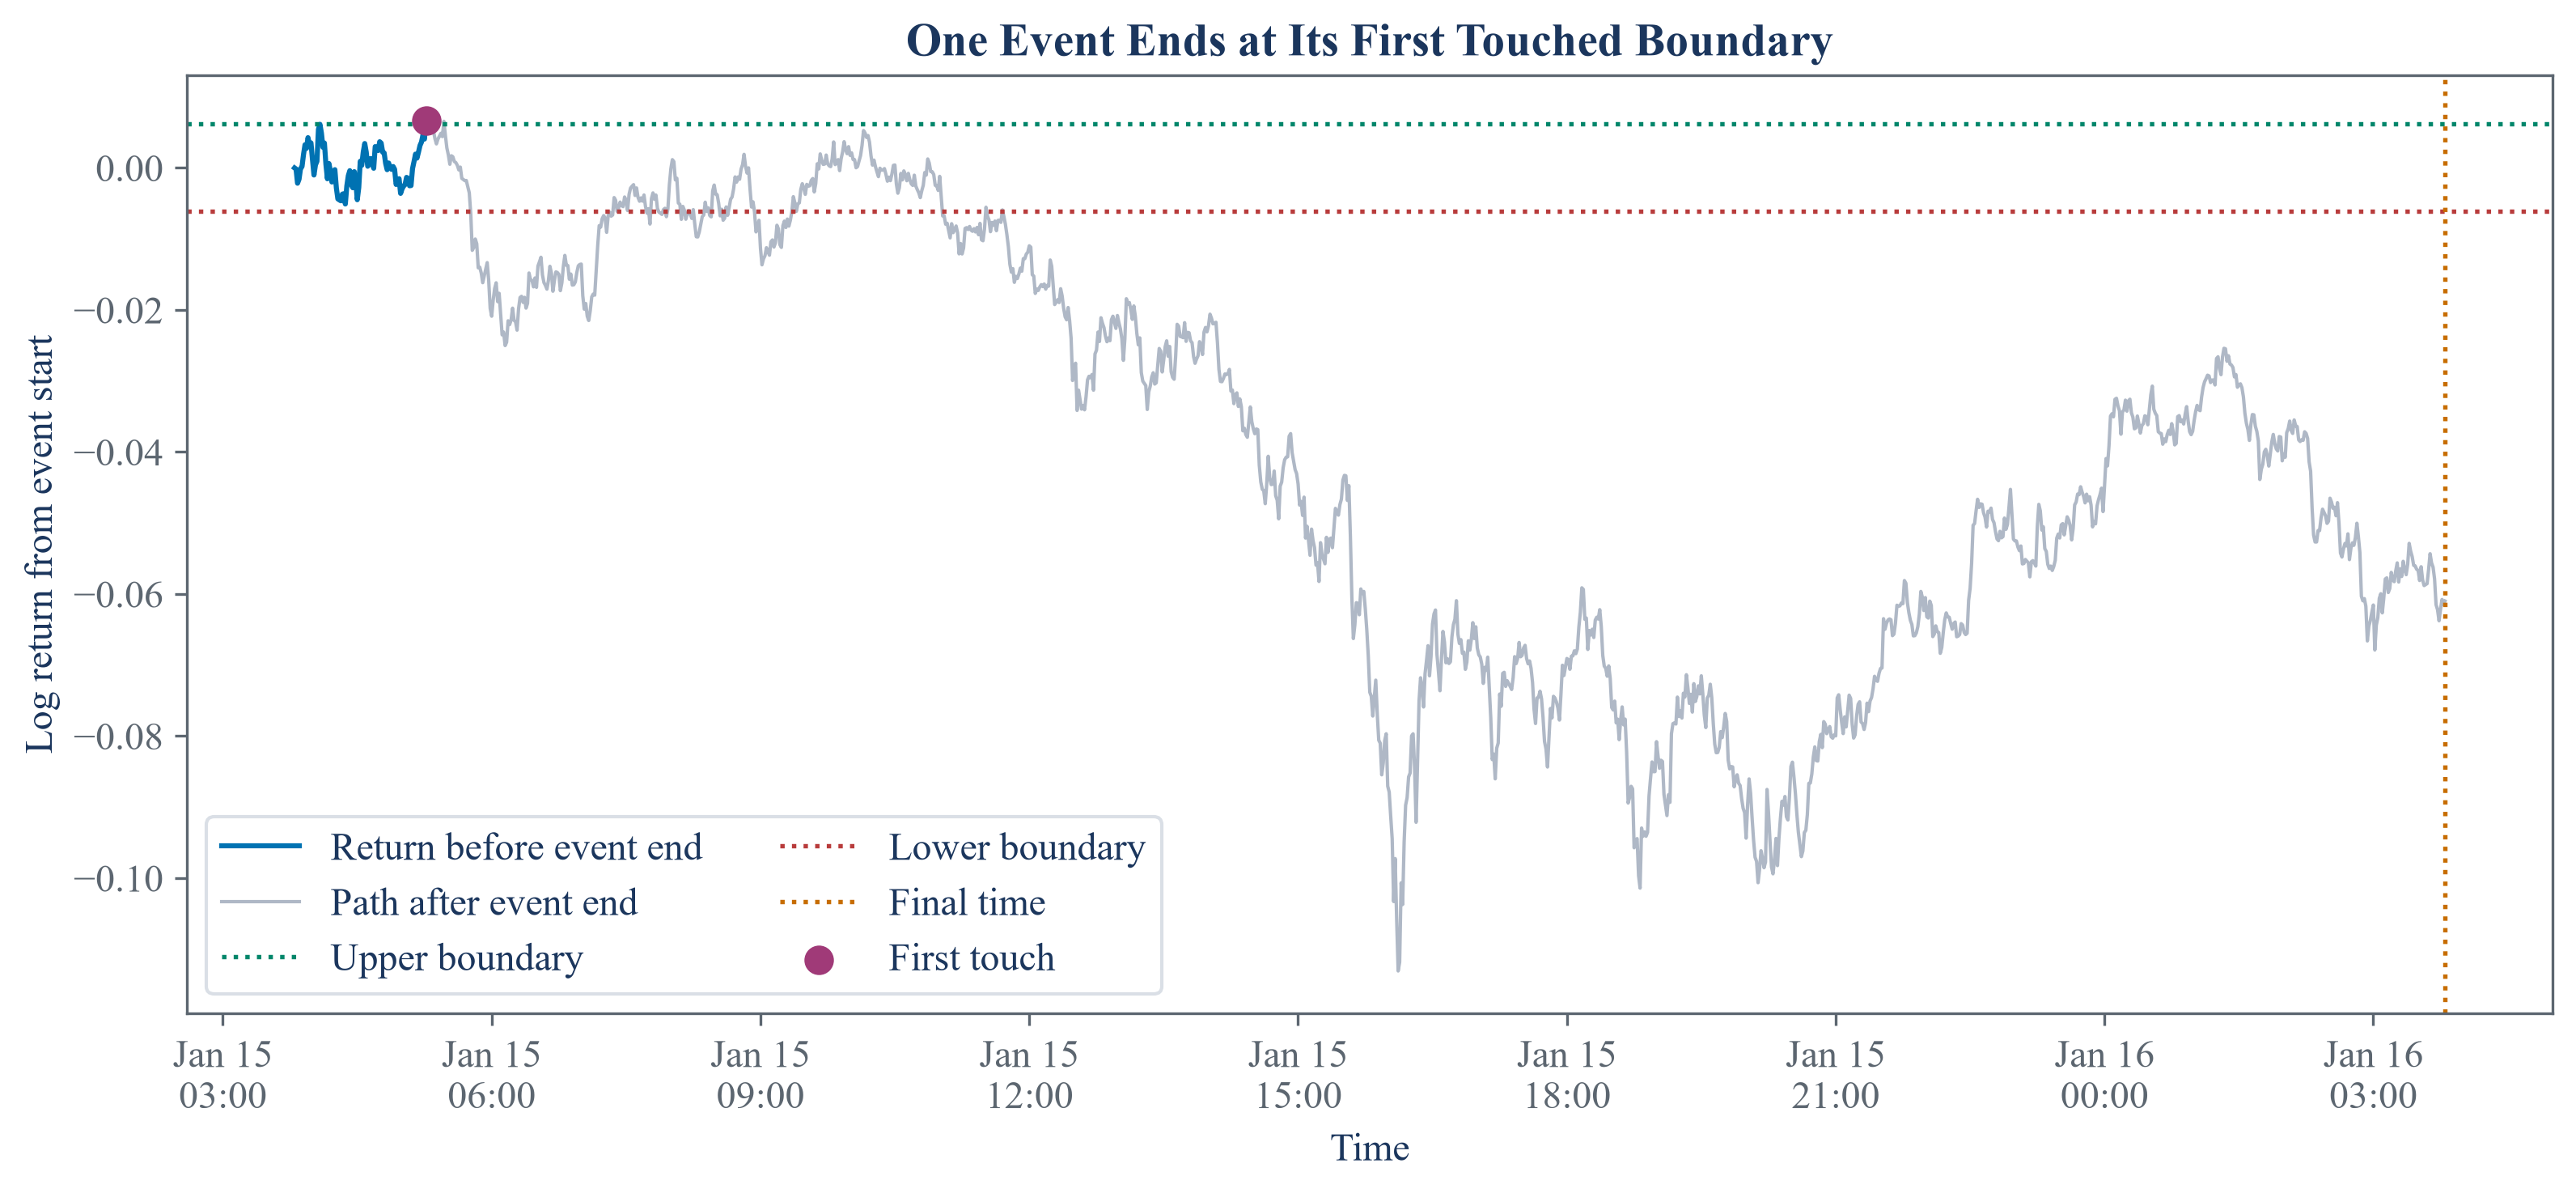

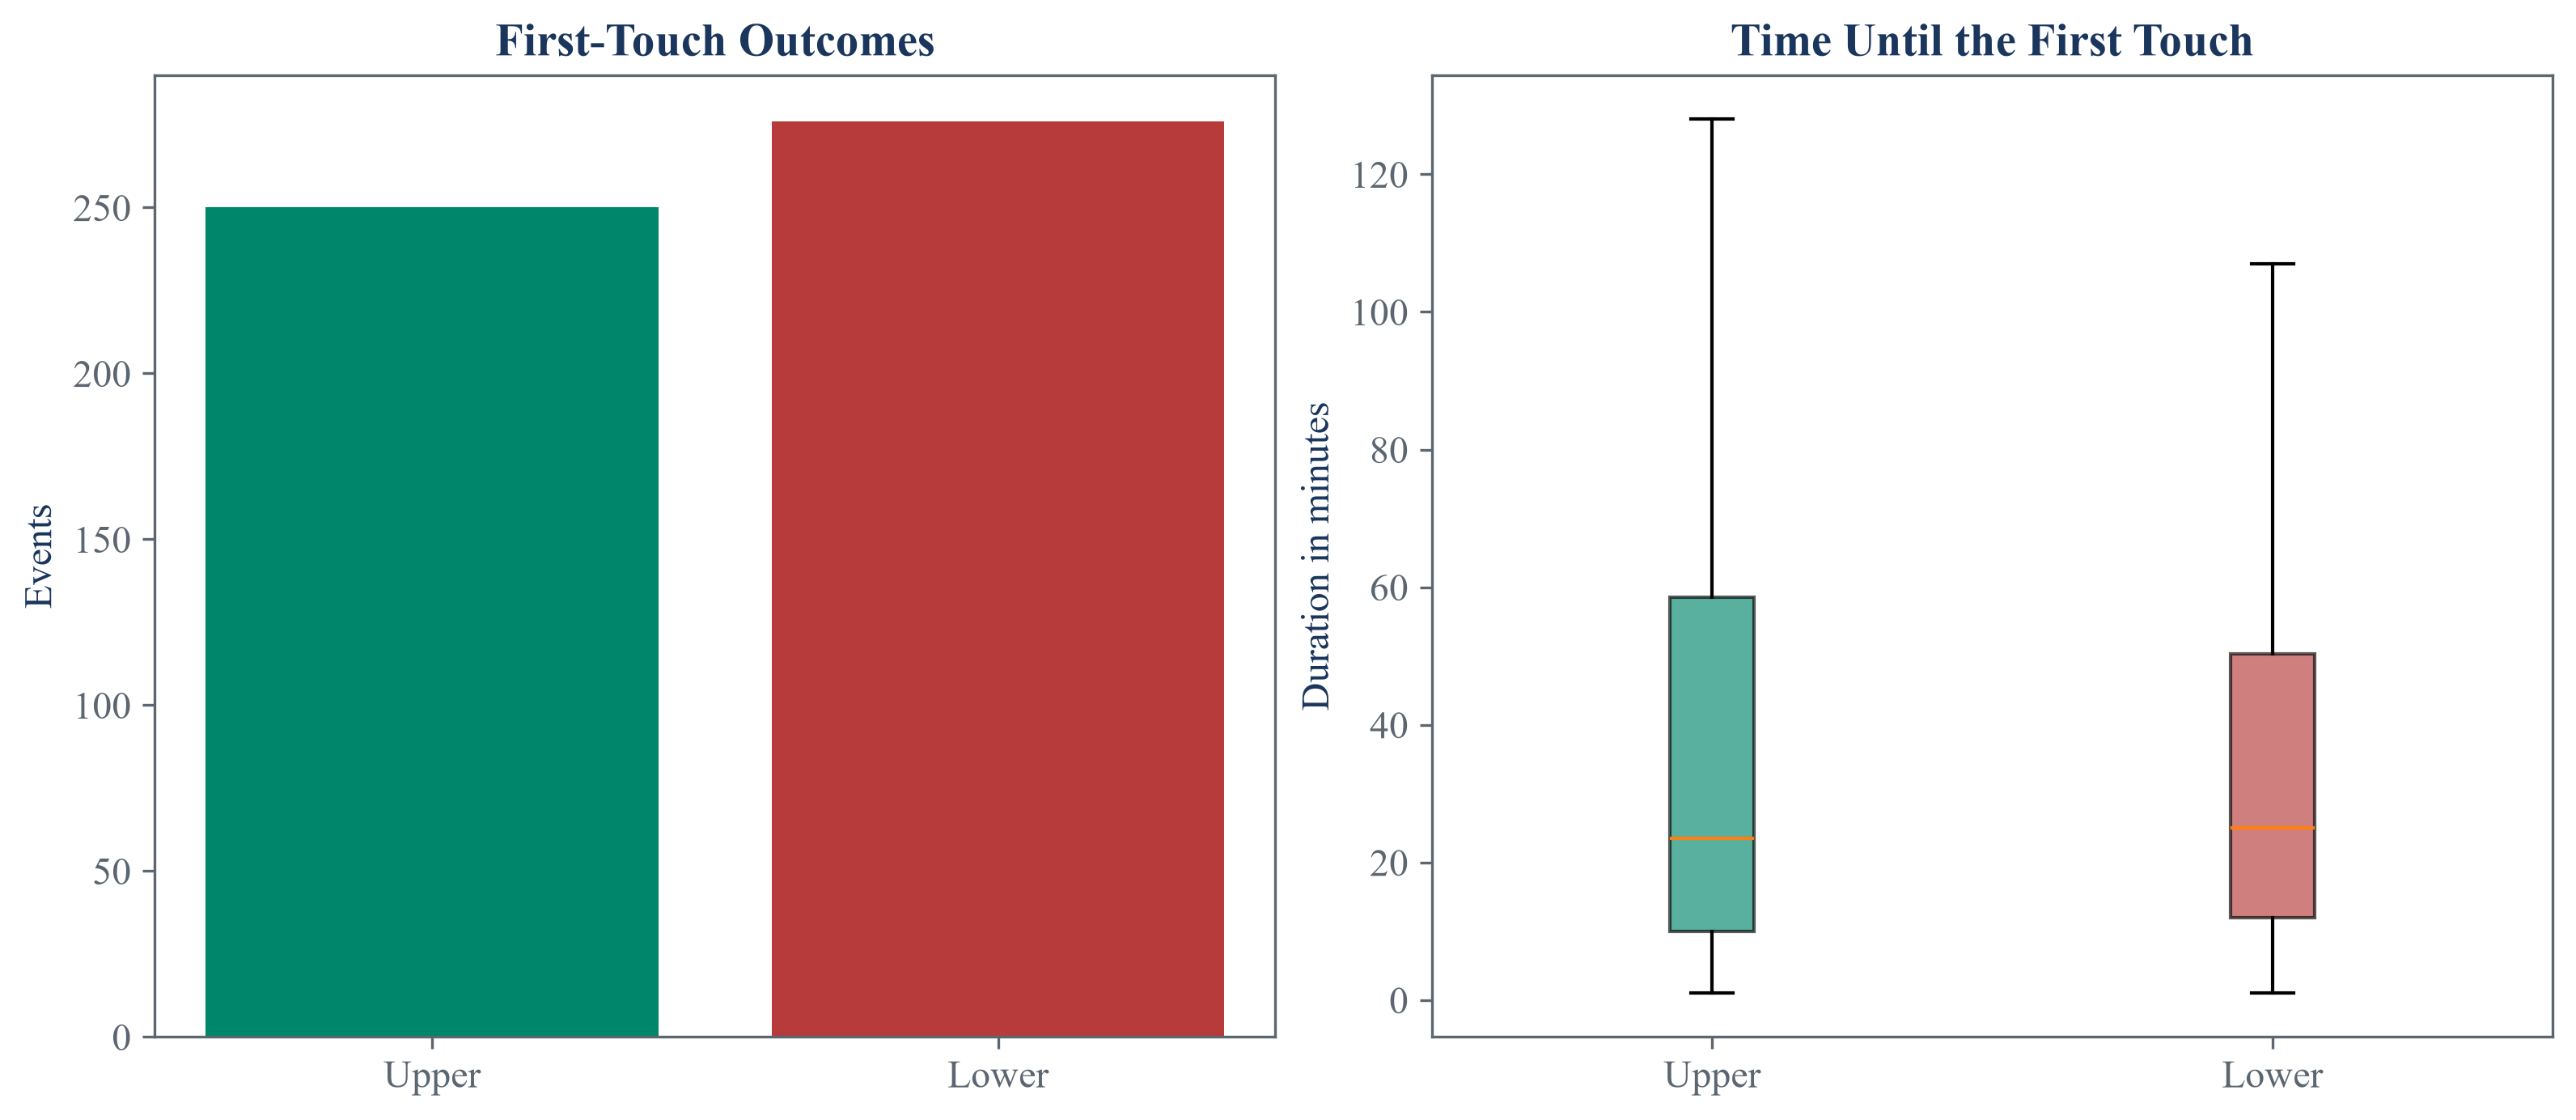

In [4]:
eligible_examples = event_results.loc[(event_results["Outcome"] != "Time") & event_results["Duration in minutes"].between(60, 720)]
example_start = eligible_examples.index[len(eligible_examples) // 2]
example_end = event_results.loc[example_start, "End Time"]
example_final = base_events.loc[example_start, "End Time"]
example_width = base_events.loc[example_start, "Base Width"]
example_path = np.log(close.loc[example_start:example_final] / close.loc[example_start])

figure, axis = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axis.plot(example_path.loc[:example_end].index, example_path.loc[:example_end], color=palette["cyan"], linewidth=1.5, label="Return before event end")
axis.plot(example_path.loc[example_end:].index, example_path.loc[example_end:], color=palette["text"], linewidth=1.0, alpha=0.35, label="Path after event end")
axis.axhline(example_width, color=palette["green"], linewidth=1.3, linestyle=":", label="Upper boundary")
axis.axhline(-example_width, color=palette["rose"], linewidth=1.3, linestyle=":", label="Lower boundary")
axis.axvline(example_final, color=palette["amber"], linewidth=1.3, linestyle=":", label="Final time")
axis.scatter([example_end], [example_path.loc[example_end]], color=palette["violet"], s=60, zorder=5, label="First touch")
axis.set_xlabel("Time")
axis.set_ylabel("Log return from event start")
axis.set_title("One Event Ends at Its First Touched Boundary")
axis.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
axis.legend(ncol=2)
figure.savefig(FIGURES / "triple_barrier_first_touch.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "triple_barrier_first_touch.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "triple_barrier_first_touch.png")))
plt.close(figure)

outcome_order = [value for value in ["Upper", "Lower", "Time"] if value in event_results["Outcome"].unique()]
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
counts = event_results["Outcome"].value_counts().reindex(outcome_order)
axes[0].bar(counts.index, counts.values, color=[palette["green"], palette["rose"], palette["amber"]][:len(counts)])
axes[0].set_ylabel("Events")
axes[0].set_title("First-Touch Outcomes")
duration_groups = [event_results.loc[event_results["Outcome"] == outcome, "Duration in minutes"] for outcome in outcome_order]
box = axes[1].boxplot(duration_groups, tick_labels=outcome_order, patch_artist=True, showfliers=False)
for patch, color in zip(box["boxes"], [palette["green"], palette["rose"], palette["amber"]]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
axes[1].set_ylabel("Duration in minutes")
axes[1].set_title("Time Until the First Touch")
figure.savefig(FIGURES / "first_touch_outcomes.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "first_touch_outcomes.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "first_touch_outcomes.png")))
plt.close(figure)

## Full-Sample Event View

,Outcome,Events,Mean log return,Return standard deviation,Middle log return,Smallest log return,Largest log return
0,Lower,276,-0.011308,0.005063,-0.010133,-0.037640,-0.003516
1,Upper,250,0.011493,0.005948,0.010099,0.002606,0.034000


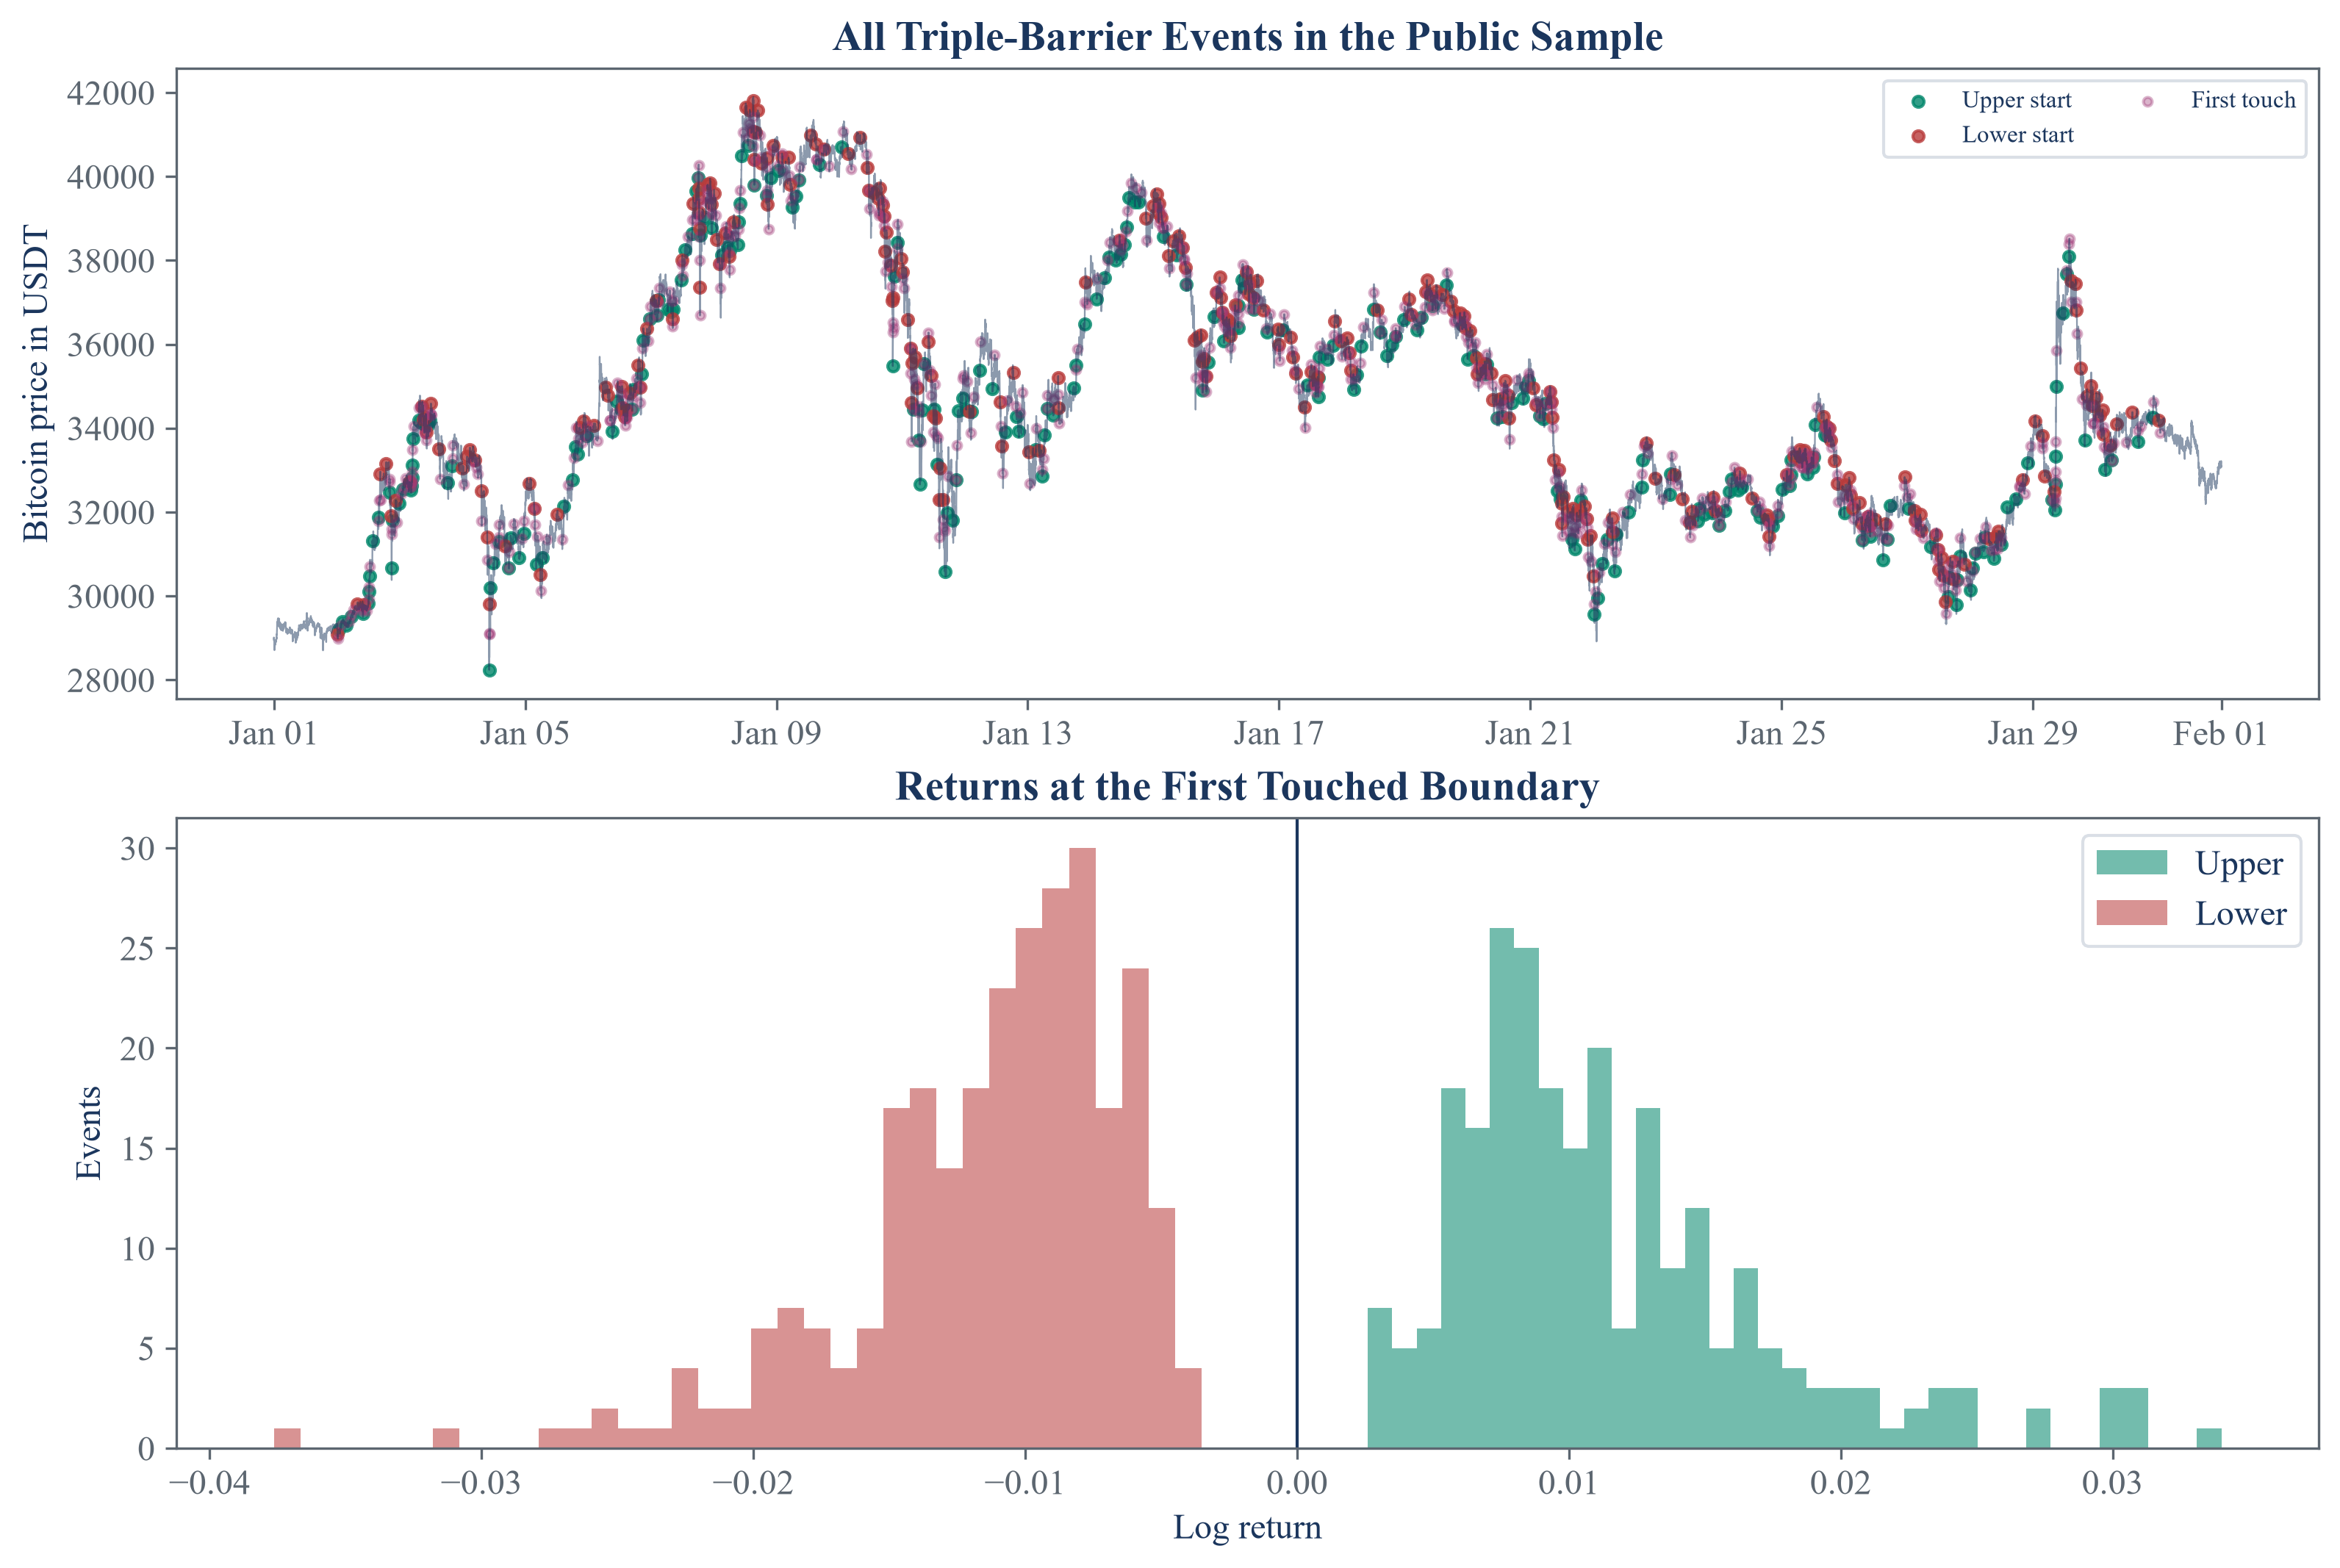

In [5]:
event_return_summary = event_results.groupby("Outcome")["Return"].agg(["count", "mean", "std", "median", "min", "max"]).reset_index()
event_return_summary.columns = ["Outcome", "Events", "Mean log return", "Return standard deviation", "Middle log return", "Smallest log return", "Largest log return"]
save_table(event_return_summary, "event_return_summary", "Return summaries for all first-touch outcomes.", "tab:chapter5-event-return-summary", fit=True)
display(event_return_summary.round(6))

outcome_colors = {"Upper": palette["green"], "Lower": palette["rose"], "Time": palette["amber"]}
figure, axes = plt.subplots(2, 1, figsize=(10.5, 7.0), constrained_layout=True)
axes[0].plot(close.index, close, color=palette["text"], linewidth=0.55, alpha=0.50)
for outcome in outcome_order:
    current = event_results[event_results["Outcome"] == outcome]
    axes[0].scatter(current.index, close.reindex(current.index), color=outcome_colors[outcome], s=13, alpha=0.80, label=f"{outcome} start")
axes[0].scatter(event_results["End Time"], close.reindex(event_results["End Time"]), color=palette["violet"], s=8, alpha=0.38, label="First touch")
axes[0].set_title("All Triple-Barrier Events in the Public Sample")
axes[0].set_ylabel("Bitcoin price in USDT")
axes[0].legend(ncol=2, fontsize=8)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for outcome in outcome_order:
    values = event_results.loc[event_results["Outcome"] == outcome, "Return"]
    axes[1].hist(values, bins=35, alpha=0.55, color=outcome_colors[outcome], label=outcome)
axes[1].axvline(0.0, color=palette["text"], linewidth=1.0)
axes[1].set_title("Returns at the First Touched Boundary")
axes[1].set_xlabel("Log return")
axes[1].set_ylabel("Events")
axes[1].legend()
figure.savefig(FIGURES / "full_sample_barrier_events.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "full_sample_barrier_events.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "full_sample_barrier_events.png")))
plt.close(figure)

## Tests

In [6]:
def reference_first_touch(price_series, events, multipliers, event_index):
    selected = events.loc[event_index]
    output = pd.DataFrame(index=selected.index)
    output["End Time"] = selected["End Time"]
    upper = multipliers[0] * selected["Base Width"] if multipliers[0] > 0 else pd.Series(np.inf, index=selected.index)
    lower = -multipliers[1] * selected["Base Width"] if multipliers[1] > 0 else pd.Series(-np.inf, index=selected.index)
    sides = selected.get("Side", pd.Series(1.0, index=selected.index))
    for start, final in selected["End Time"].fillna(price_series.index[-1]).items():
        path = np.log(price_series.loc[start:final] / price_series.loc[start]) * sides.loc[start]
        lower_time = path[path < lower.loc[start]].index.min()
        upper_time = path[path > upper.loc[start]].index.min()
        output.loc[start, "Lower"] = lower_time
        output.loc[start, "Upper"] = upper_time
    output["End Time"] = output.min(axis=1)
    return output[["End Time"]]

random_generator = np.random.default_rng(11)
for repetition in range(25):
    observation_count = int(random_generator.integers(60, 300))
    index = pd.date_range("2020-01-01", periods=observation_count, freq="min")
    random_close = pd.Series(np.cumprod(1.0 + random_generator.standard_normal(observation_count) * 0.01) * 100.0, index=index)
    positions = np.sort(random_generator.choice(observation_count - 2, size=int(random_generator.integers(3, 25)), replace=False))
    finals = [pd.NaT if random_generator.random() < 0.25 else index[min(position + int(random_generator.integers(1, 30)), observation_count - 1)] for position in positions]
    random_events = pd.DataFrame({"End Time": pd.to_datetime(finals), "Base Width": random_generator.uniform(0.005, 0.05, size=len(positions)), "Side": random_generator.choice([1.0, -1.0], size=len(positions))}, index=index[positions])
    multipliers = [float(random_generator.uniform(0.5, 2.0)), float(random_generator.uniform(0.5, 2.0))]
    observed = triple_barrier(random_close, random_events, multipliers, list(random_events.index))
    expected = reference_first_touch(random_close, random_events, multipliers, list(random_events.index))
    pd.testing.assert_series_equal(observed["End Time"], expected["End Time"], check_names=False, check_dtype=False)

assert controlled_passages["Expected outcome"].equals(controlled_passages["Observed outcome"])
assert len(event_results) > 0
assert event_results["End Time"].notna().all()
assert np.all(event_results["End Time"] <= base_events.loc[event_results.index, "End Time"])
assert np.all(event_results.loc[event_results["Outcome"] == "Upper", "Return"] > event_results.loc[event_results["Outcome"] == "Upper", "Base Width"])
assert np.all(event_results.loc[event_results["Outcome"] == "Lower", "Return"] < -event_results.loc[event_results["Outcome"] == "Lower", "Base Width"])
assert np.all(event_results.loc[event_results["Outcome"] == "Time", "End Time"] == base_events.loc[event_results.index[event_results["Outcome"] == "Time"], "End Time"])
assert set(labels["Label"].unique()).issubset({-1.0, 0.0, 1.0})
assert outcome_summary["Events"].sum() == len(event_results)
assert np.isclose(outcome_summary["Share"].sum(), 1.0)
assert event_return_summary["Events"].sum() == len(event_results)
assert set(event_return_summary["Outcome"]) == set(event_results["Outcome"])
assert (FIGURES / "full_sample_barrier_events.pdf").is_file()
assert (TABLES / "event_return_summary.tex").is_file()